# Linear and Polynomial Regression
**MOD008909 Big Data Analytics, Week 8**

**Tasks**
1. Load the data and shape it (X = predictors, y = target)
2. Train/test split
3. Linear regression, polynomial regression (degree 2 and 3)
4. Metrics (RMSE, R²)
5. Predicted vs actual scatter plots

Part A data: UK local-authority population by age band (`sexDensitiesMale.csv`, `sexDensitiesFemale.csv`). Part B data: Life Expectancy (WHO) from Kaggle.
**Part A** is worked for you. **Part B** repeats the same steps on the Life Expectancy data.

## Setup

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

DATA_DIR = "data"
print("Ready")

Ready


# Part A: worked example
**Question:** can the share of people aged over 61 in a local authority be predicted from the shares of younger age groups?

## A1. Load the data

In [2]:
male = pd.read_csv(f"{DATA_DIR}/sexDensitiesMale.csv")
female = pd.read_csv(f"{DATA_DIR}/sexDensitiesFemale.csv")
ages = male.merge(female, on="CODE", suffixes=("_m", "_f"))

print("rows:", len(ages))
print(ages[["CODE", "Location_m", "AllAges_m", "<18_m", "26-30_m", ">61_m"]].head())

rows: 439
        CODE         Location_m  AllAges_m    <18_m  26-30_m    >61_m
0  K02000001     UNITED KINGDOM   31793752  7412279  2184056  6506753
1  K03000001      GREAT BRITAIN   30891041  7177668  2122744  6343126
2  K04000001  ENGLAND AND WALES   28294511  6617392  1948958  5793929
3  E92000001            ENGLAND   26773196  6274836  1854176  5441119
4  E12000001         NORTH EAST    1283216   286066    82491   281796


## A2. Clean and shape the data
The file mixes countries, regions, counties and local authorities. We keep **only local authority rows** (codes starting E06, E07, E08, E09, W06, S12, N09).

Then we turn counts into **percentages of each authority's population**, so large and small areas are comparable.

In [3]:
authority_codes = ("E06", "E07", "E08", "E09", "W06", "S12", "N09")
auth = ages[ages["CODE"].str.startswith(authority_codes)].reset_index(drop=True)
total = auth["AllAges_m"] + auth["AllAges_f"]

df = pd.DataFrame({"area": auth["Location_m"]})
df["pct_under18"] = 100 * (auth["<18_m"] + auth["<18_f"]) / total
df["pct_19_25"] = 100 * (auth["19-25_m"] + auth["19-25_f"]) / total
df["pct_26_30"] = 100 * (auth["26-30_m"] + auth["26-30_f"]) / total
df["pct_31_35"] = 100 * (auth["31-35_m"] + auth["31-35_f"]) / total
df["pct_35_45"] = 100 * (auth["35-45_m"] + auth["35-45_f"]) / total
df["pct_old"] = 100 * (auth[">61_m"] + auth[">61_f"]) / total

df = df.dropna().reset_index(drop=True)
print(df.head())
print("\nRows:", len(df))

             area  pct_under18  pct_19_25  pct_26_30  pct_31_35  pct_35_45  \
0   County Durham    20.563452   9.878074   5.771641   5.828616  12.043695   
1      Darlington    22.735771   7.604848   6.070212   6.167016  12.929095   
2      Hartlepool    22.843720   8.708284   6.447781   5.790042  11.838211   
3   Middlesbrough    24.203020  11.886227   7.014139   6.122816  11.480100   
4  Northumberland    20.069497   6.972439   5.133756   5.222683  11.705545   

     pct_old  
0  24.584905  
1  23.766454  
2  23.206610  
3  19.901667  
4  28.161285  

Rows: 390


In [4]:
feature_cols = ["pct_under18", "pct_19_25", "pct_26_30", "pct_31_35", "pct_35_45"]
X = df[feature_cols].values
y = df["pct_old"].values

print("X shape:", X.shape, "  y shape:", y.shape)

X shape: (390, 5)   y shape: (390,)


`pct_45_60` is left out on purpose: the age shares add up to 100%, so using all of them would give the model the answer by subtraction.

## A3. Train/test split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("train rows:", len(X_train), "  test rows:", len(X_test))

train rows: 292   test rows: 98


## A4. Linear regression baseline

In [6]:
lin = LinearRegression()
lin.fit(X_train, y_train)

y_pred_lin = lin.predict(X_test)
rmse_lin = math.sqrt(mean_squared_error(y_test, y_pred_lin))
r2_lin = r2_score(y_test, y_pred_lin)

print(f"Linear Regression - RMSE: {rmse_lin:.2f}, R²: {r2_lin:.3f}")
print("Coefficients:")
print(f"   pct_under18  {lin.coef_[0]:8.3f}")
print(f"   pct_19_25    {lin.coef_[1]:8.3f}")
print(f"   pct_26_30    {lin.coef_[2]:8.3f}")
print(f"   pct_31_35    {lin.coef_[3]:8.3f}")
print(f"   pct_35_45    {lin.coef_[4]:8.3f}")
print("Intercept:", round(lin.intercept_, 3))

Linear Regression - RMSE: 0.75, R²: 0.970
Coefficients:
   pct_under18    -0.778
   pct_19_25      -0.754
   pct_26_30      -1.139
   pct_31_35       0.231
   pct_35_45      -1.672
Intercept: 74.466


RMSE is the typical size of a miss, in the same units as y (percentage points). R² is the share of the variation the model explains (1 = perfect, 0 = no better than the average).

## A5. Polynomial regression (degree 2 and 3)
`PolynomialFeatures` adds squares and products of the features so the model can bend. `StandardScaler` puts all the columns on the same scale. We fit the training data, then apply the same steps to the test data.

### Degree 2

In [7]:
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_p2 = poly2.fit_transform(X_train)
X_test_p2 = poly2.transform(X_test)

scaler2 = StandardScaler()
X_train_s2 = scaler2.fit_transform(X_train_p2)
X_test_s2 = scaler2.transform(X_test_p2)

lin2 = LinearRegression()
lin2.fit(X_train_s2, y_train)
p2 = lin2.predict(X_test_s2)
print(f"Plain poly d=2 - RMSE: {math.sqrt(mean_squared_error(y_test, p2)):.2f}, R²: {r2_score(y_test, p2):.3f}")

Plain poly d=2 - RMSE: 0.67, R²: 0.976


### Degree 3

In [8]:
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_p3 = poly3.fit_transform(X_train)
X_test_p3 = poly3.transform(X_test)

scaler3 = StandardScaler()
X_train_s3 = scaler3.fit_transform(X_train_p3)
X_test_s3 = scaler3.transform(X_test_p3)

lin3 = LinearRegression()
lin3.fit(X_train_s3, y_train)
p3 = lin3.predict(X_test_s3)
print(f"Plain poly d=3 - RMSE: {math.sqrt(mean_squared_error(y_test, p3)):.2f}, R²: {r2_score(y_test, p3):.3f}")

Plain poly d=3 - RMSE: 1.00, R²: 0.947


With 5 features, degree 2 creates 20 columns and degree 3 creates 55. More columns means more room to fit noise, so degree 3 can get worse on new data.

### Ridge (regularised) version
`RidgeCV` adds a penalty on large coefficients and picks the penalty strength `alpha` itself. We use it on the same scaled features.

In [9]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

ridge2 = RidgeCV(alphas=alphas)
ridge2.fit(X_train_s2, y_train)
p2r = ridge2.predict(X_test_s2)
print(f"Poly d=2 (RidgeCV) - RMSE: {math.sqrt(mean_squared_error(y_test, p2r)):.2f}, R²: {r2_score(y_test, p2r):.3f}, alpha: {ridge2.alpha_}")

ridge3 = RidgeCV(alphas=alphas)
ridge3.fit(X_train_s3, y_train)
p3r = ridge3.predict(X_test_s3)
print(f"Poly d=3 (RidgeCV) - RMSE: {math.sqrt(mean_squared_error(y_test, p3r)):.2f}, R²: {r2_score(y_test, p3r):.3f}, alpha: {ridge3.alpha_}")

Poly d=2 (RidgeCV) - RMSE: 0.68, R²: 0.976, alpha: 0.1
Poly d=3 (RidgeCV) - RMSE: 0.67, R²: 0.976, alpha: 0.1


## A6. Predicted vs actual

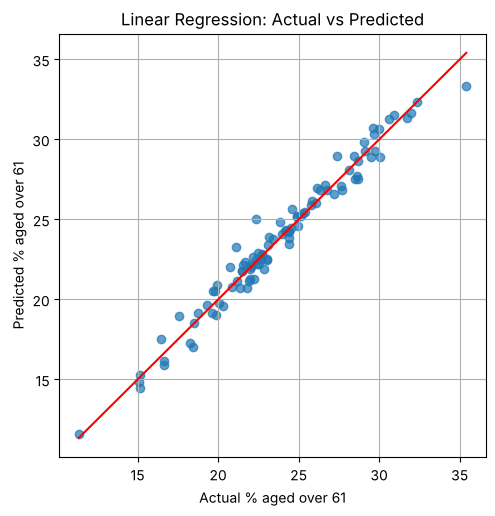

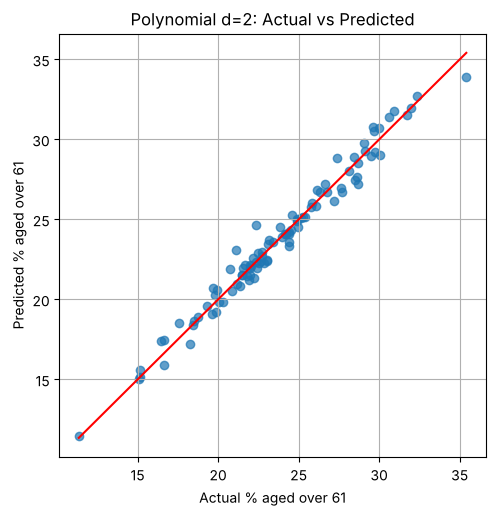

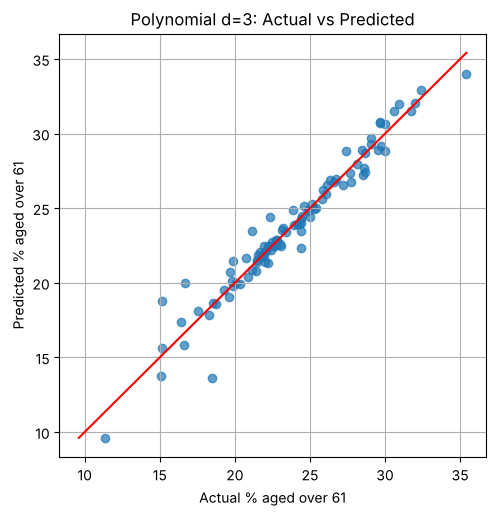

In [10]:
def plot_pred_vs_actual(y_true, y_pred, title):
    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(y_true, y_pred, alpha=0.7)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    plt.plot(lims, lims, color="red")          # perfect predictions lie on this line
    plt.xlabel("Actual % aged over 61")
    plt.ylabel("Predicted % aged over 61")
    plt.title(title)
    plt.grid(True)
    plt.show()

plot_pred_vs_actual(y_test, y_pred_lin, "Linear Regression: Actual vs Predicted")
plot_pred_vs_actual(y_test, p2, "Polynomial d=2: Actual vs Predicted")
plot_pred_vs_actual(y_test, p3, "Polynomial d=3: Actual vs Predicted")

## A7. A naïve baseline for context
A model is only useful if it beats something very simple. Naïve baseline: always predict the **average of the training target**.

In [11]:
y_pred_naive = np.full(len(y_test), y_train.mean())
rmse_naive = math.sqrt(mean_squared_error(y_test, y_pred_naive))
r2_naive = r2_score(y_test, y_pred_naive)
print(f"Naive (always the training average) - RMSE: {rmse_naive:.2f}, R²: {r2_naive:.3f}")

summary = pd.DataFrame({
    "model": ["Naive average", "Linear", "Poly d=2", "Poly d=3", "Poly d=2 (RidgeCV)", "Poly d=3 (RidgeCV)"],
    "test_RMSE": [rmse_naive, rmse_lin,
                  math.sqrt(mean_squared_error(y_test, p2)), math.sqrt(mean_squared_error(y_test, p3)),
                  math.sqrt(mean_squared_error(y_test, p2r)), math.sqrt(mean_squared_error(y_test, p3r))],
    "test_R2": [r2_naive, r2_lin, r2_score(y_test, p2), r2_score(y_test, p3),
                r2_score(y_test, p2r), r2_score(y_test, p3r)],
}).round(3)
print()
print(summary.to_string(index=False))

Naive (always the training average) - RMSE: 4.37, R²: -0.006

             model  test_RMSE  test_R2
     Naive average      4.372   -0.006
            Linear      0.749    0.970
          Poly d=2      0.673    0.976
          Poly d=3      1.003    0.947
Poly d=2 (RidgeCV)      0.680    0.976
Poly d=3 (RidgeCV)      0.669    0.976


**Reading the table.** Lower RMSE and higher R² are better. If the polynomial models barely beat the linear model, the simpler linear model is the better choice.

The scores are very high partly because the age shares add up to 100%: once you know most of the shares, the last one is largely fixed. That is arithmetic, not a discovery about behaviour.

Everything here is about *areas*, not individual people.

---
# Part B: your turn, on the Life Expectancy data
Repeat the same steps on **Life Expectancy (WHO)** (Kaggle, KumarRajarshi). It has one row per country per year, with health, schooling and economic measures. The file is saved in the `data` folder as `Life Expectancy Data.csv`.

**Your task:** predict **life expectancy** from other numeric columns, using the steps from Part A.

## B1. Load and clean

In [12]:
life = pd.read_csv(f"{DATA_DIR}/Life Expectancy Data.csv")
life.columns = life.columns.str.strip()      # the original file has stray spaces in column names
print("rows:", len(life), "  columns:", len(life.columns))
print(list(life.columns))
print()
print(life.isna().sum()[life.isna().sum() > 0])

rows: 2938   columns: 22
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']

Life expectancy                     10
Adult Mortality                     10
Alcohol                            194
Hepatitis B                        553
BMI                                 34
Polio                               19
Total expenditure                  226
Diphtheria                          19
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64


**Your answers (B1):**
1. What does one row represent?
2. Which columns have missing values? What will you do about them (drop rows, fill in)? Say why.

## B2. Choose features and shape the data

In [13]:
target_col = "Life expectancy"
feature_cols_b = ["Adult Mortality", "BMI", "Schooling", "Income composition of resources", "HIV/AIDS"]

life_b = life[feature_cols_b + [target_col]].dropna().reset_index(drop=True)
X_b = life_b[feature_cols_b].values
y_b = life_b[target_col].values
print("rows kept:", len(life_b), "of", len(life))

rows kept: 2736 of 2938


**Your answer:** why did you choose those features? What sign do you expect for each coefficient?

## B3. Train/test split, then linear regression

In [14]:
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_b, y_b, test_size=0.25, random_state=42)

lin_b = LinearRegression()
lin_b.fit(Xb_train, yb_train)
yb_pred_lin = lin_b.predict(Xb_test)
rmse_b_lin = math.sqrt(mean_squared_error(yb_test, yb_pred_lin))
r2_b_lin = r2_score(yb_test, yb_pred_lin)

print(f"Linear Regression - RMSE: {rmse_b_lin:.2f}, R²: {r2_b_lin:.3f}")
print("Coefficients:")
print(f"   Adult Mortality                  {lin_b.coef_[0]:8.3f}")
print(f"   BMI                              {lin_b.coef_[1]:8.3f}")
print(f"   Schooling                        {lin_b.coef_[2]:8.3f}")
print(f"   Income composition of resources  {lin_b.coef_[3]:8.3f}")
print(f"   HIV/AIDS                         {lin_b.coef_[4]:8.3f}")

Linear Regression - RMSE: 4.12, R²: 0.814
Coefficients:
   Adult Mortality                    -0.019
   BMI                                 0.050
   Schooling                           1.045
   Income composition of resources     8.513
   HIV/AIDS                           -0.525


**Your answer:** do the coefficient signs match what you expected? Write the RMSE as a sentence ("on average the prediction is off by ... years").

## B4. Polynomial regression (degree 2 and 3)
### Degree 2

In [15]:
polyb2 = PolynomialFeatures(degree=2, include_bias=False)
Xb_train_p2 = polyb2.fit_transform(Xb_train)
Xb_test_p2 = polyb2.transform(Xb_test)

scalerb2 = StandardScaler()
Xb_train_s2 = scalerb2.fit_transform(Xb_train_p2)
Xb_test_s2 = scalerb2.transform(Xb_test_p2)

linb2 = LinearRegression()
linb2.fit(Xb_train_s2, yb_train)
pb2 = linb2.predict(Xb_test_s2)
print(f"Poly d=2 - RMSE: {math.sqrt(mean_squared_error(yb_test, pb2)):.2f}, R²: {r2_score(yb_test, pb2):.3f}")

Poly d=2 - RMSE: 3.10, R²: 0.895


### Degree 3

In [16]:
polyb3 = PolynomialFeatures(degree=3, include_bias=False)
Xb_train_p3 = polyb3.fit_transform(Xb_train)
Xb_test_p3 = polyb3.transform(Xb_test)

scalerb3 = StandardScaler()
Xb_train_s3 = scalerb3.fit_transform(Xb_train_p3)
Xb_test_s3 = scalerb3.transform(Xb_test_p3)

linb3 = LinearRegression()
linb3.fit(Xb_train_s3, yb_train)
pb3 = linb3.predict(Xb_test_s3)
print(f"Poly d=3 - RMSE: {math.sqrt(mean_squared_error(yb_test, pb3)):.2f}, R²: {r2_score(yb_test, pb3):.3f}")

Poly d=3 - RMSE: 2.75, R²: 0.917


### Ridge (RidgeCV) on the same features

In [17]:
ridgeb2 = RidgeCV(alphas=alphas)
ridgeb2.fit(Xb_train_s2, yb_train)
pb2r = ridgeb2.predict(Xb_test_s2)
print(f"Poly d=2 (RidgeCV) - RMSE: {math.sqrt(mean_squared_error(yb_test, pb2r)):.2f}, R²: {r2_score(yb_test, pb2r):.3f}, alpha: {ridgeb2.alpha_}")

ridgeb3 = RidgeCV(alphas=alphas)
ridgeb3.fit(Xb_train_s3, yb_train)
pb3r = ridgeb3.predict(Xb_test_s3)
print(f"Poly d=3 (RidgeCV) - RMSE: {math.sqrt(mean_squared_error(yb_test, pb3r)):.2f}, R²: {r2_score(yb_test, pb3r):.3f}, alpha: {ridgeb3.alpha_}")

Poly d=2 (RidgeCV) - RMSE: 3.10, R²: 0.895, alpha: 0.1


Poly d=3 (RidgeCV) - RMSE: 2.72, R²: 0.919, alpha: 0.1


## B5. Predicted vs actual, naïve baseline, summary

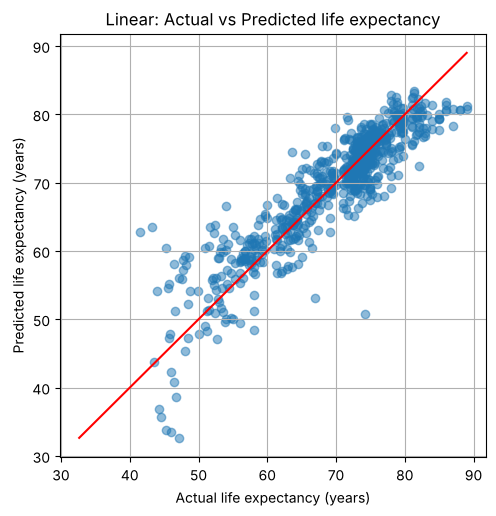

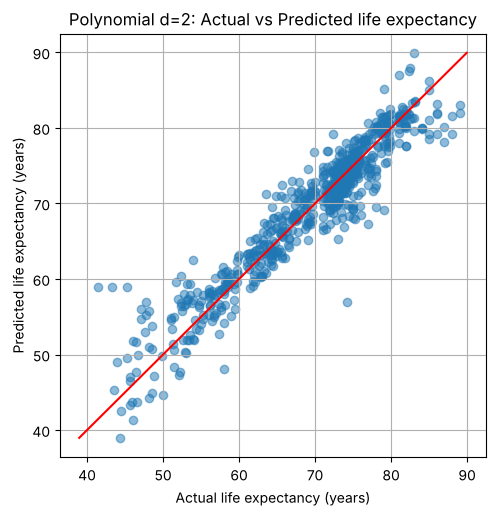

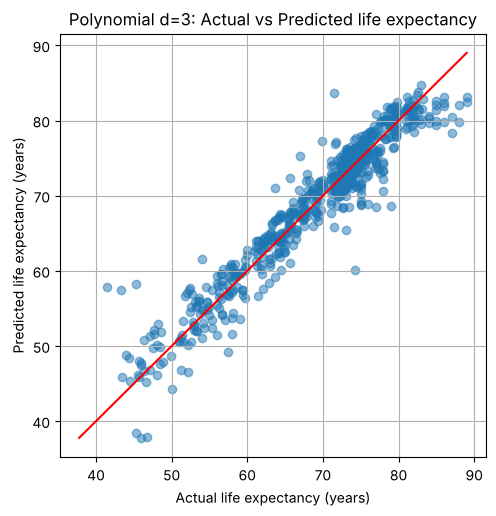

In [18]:
def plot_life(y_true, y_pred, title):
    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(y_true, y_pred, alpha=0.5)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    plt.plot(lims, lims, color="red")
    plt.xlabel("Actual life expectancy (years)")
    plt.ylabel("Predicted life expectancy (years)")
    plt.title(title)
    plt.grid(True)
    plt.show()

plot_life(yb_test, yb_pred_lin, "Linear: Actual vs Predicted life expectancy")
plot_life(yb_test, pb2, "Polynomial d=2: Actual vs Predicted life expectancy")
plot_life(yb_test, pb3, "Polynomial d=3: Actual vs Predicted life expectancy")

In [19]:
naive_b = np.full(len(yb_test), yb_train.mean())
rmse_naive_b = math.sqrt(mean_squared_error(yb_test, naive_b))
r2_naive_b = r2_score(yb_test, naive_b)
print(f"Naive - RMSE: {rmse_naive_b:.2f}, R²: {r2_naive_b:.3f}")

summary_b = pd.DataFrame({
    "model": ["Naive average", "Linear", "Poly d=2", "Poly d=3", "Poly d=2 (RidgeCV)", "Poly d=3 (RidgeCV)"],
    "test_RMSE": [rmse_naive_b, rmse_b_lin,
                  math.sqrt(mean_squared_error(yb_test, pb2)), math.sqrt(mean_squared_error(yb_test, pb3)),
                  math.sqrt(mean_squared_error(yb_test, pb2r)), math.sqrt(mean_squared_error(yb_test, pb3r))],
    "test_R2": [r2_naive_b, r2_b_lin, r2_score(yb_test, pb2), r2_score(yb_test, pb3),
                r2_score(yb_test, pb2r), r2_score(yb_test, pb3r)],
}).round(3)
print()
print(summary_b.to_string(index=False))

Naive - RMSE: 9.55, R²: -0.002

             model  test_RMSE  test_R2
     Naive average      9.551   -0.002
            Linear      4.117    0.814
          Poly d=2      3.095    0.895
          Poly d=3      2.746    0.917
Poly d=2 (RidgeCV)      3.095    0.895
Poly d=3 (RidgeCV)      2.715    0.919


## B6. Think about it
1. Does your best model beat the naïve baseline? By how much, in years?
2. Is the polynomial model worth it compared with the linear one?
3. Each country appears many times (one row per year). A random split puts the same country in both train and test. Why might that make the scores look better than they would for a country the model has never seen?
4. Does a high coefficient for `Schooling` mean more schooling *causes* longer life? What else could explain it?
5. **Extension:** try one more feature set (add or remove columns). What changed in test RMSE?